# All sites plot Land Exposure compared to Low Tide

For the selected date range, process Sentinel-2 scenes with less than 10% catalogue cloud cover at all configured sites. For each scene, record the nearest predicted low-tide time, height, and signed time offset; estimate whole-site dry area from SCL vegetation (class 4) and not-vegetated (class 5) pixels. Save per-site CSVs, RGB/SCL galleries, and dry-area-versus-low-tide scatter plots in each site's output folder.

In [2]:
import base64
import datetime
import html as html_module
import io
import os
import sys
import pathlib

import geopandas
import matplotlib.pyplot as plt
import numpy
import pandas
import plotly.express as px
import rasterio
import rasterio.features
import xarray
from IPython.display import FileLink, display

module_path = pathlib.Path.cwd().parent / 'scripts'
import sys
if str(module_path) not in sys.path:
    sys.path.append(str(module_path))
import utils
import sentinel2
import plotting

%load_ext autoreload
%autoreload 2

## Date-Range Site and Cloud Settings

Set the start and end years and cloud-cover cutoff below. All matching scenes are retained; low-tide timing is recorded for comparison, not used to exclude scenes.

In [2]:
data_path = utils.get_data_path()

In [3]:
all_training_sites =  ["Ihutai", "CatlinsLake", "CatlinsRiverMouth", "Childrens", "Duvauchelle", "Robinsons", "Takamatua", "Purau",
              "IveyBay_Nov25", "IveyBay_Feb26", "LeftBank_Nov25", "LeftBank_Feb26", "Paremata_Nov25", "Paremata_Feb26",
              "Paremata_Feb25", "ThePoint_Nov25", "ThePoint_Feb26", "Takapuwahia_Nov25", "Takapuwahia_Feb26", "IveyBay_ThePoint_LeftBank_Oct24"]
sites = all_training_sites

years = [2016, 2017, 2018, 2019, 2020, 2021, 2022, 2023, 2024, 2025, 2026]

max_cloud_cover = 1

In [4]:
_, satellite_path = utils.get_prediction_path(
    sample_method="sampling_2", method_2_threshold=0.5,
    model_max_cloud_cover=max_cloud_cover,
    predict_max_cloud_cover=max_cloud_cover,
    satellite_only=True) 

mndwi_file = satellite_path / "mean_mndwi.csv"
output_path = satellite_path / "rbg_thumbnails_mndwi_sorted"
output_path.mkdir(exist_ok=True, parents=True)

### Templ cell while other ntoebook running to completion

In [5]:
scl_classes = [
    (0, "No data", "#000000"),
    (1, "Saturated/defective", "#ff0000"),
    (2, "Dark area", "#2f2f2f"),
    (3, "Cloud shadow", "#643200"),
    (4, "Vegetation", "#00a000"),
    (5, "Not vegetated", "#ffe65a"),
    (6, "Water", "#0000ff"),
    (7, "Unclassified", "#808080"),
    (8, "Cloud, medium probability", "#c0c0c0"),
    (9, "Cloud, high probability", "#ffffff"),
    (10, "Thin cirrus", "#64c8ff"),
    (11, "Snow/ice", "#ff96ff"),
]
scl_legend_html = '<div class="legend">' + "".join(
    f'<span class="legend-item"><i style="background:{color}"></i>{code}: '
    f'{html_module.escape(label)}</span>'
    for code, label, color in scl_classes
) + "</div>"


def make_gallery(site_name, gallery_title, cards, output_file, legend_html=""):
    gallery_style = """
:root { color-scheme: light; font-family: "Segoe UI", sans-serif; color: #202a33; background: #f3f5f6; }
body { margin: 0; padding: 20px; }
header, .gallery, .legend { max-width: 1500px; margin: 0 auto 16px; }
h1 { margin: 0 0 6px; font-size: 22px; }
p { margin: 0; color: #56616b; }
.gallery { display: grid; grid-template-columns: repeat(auto-fill, minmax(min(320px, 100%), 1fr)); gap: 14px; }
.scene { min-width: 0; overflow: hidden; background: white; border: 1px solid #d5dce1; border-radius: 5px; }
.scene h2 { margin: 10px 12px 0; font-size: 15px; }
.scene img { display: block; width: 100%; aspect-ratio: 4 / 3; object-fit: contain; background: #f7f8f8; }
.caption { padding: 8px 12px 11px; font-size: 12px; line-height: 1.4; }
.legend { display: flex; flex-wrap: wrap; gap: 6px 12px; padding: 10px; background: white; border: 1px solid #d5dce1; }
.legend-item { display: inline-flex; align-items: center; gap: 5px; font-size: 11px; }
.legend-item i { display: inline-block; width: 14px; height: 14px; border: 1px solid #7b858c; }
@media (max-width: 600px) { body { padding: 10px; } }
"""
    page = f"""<!doctype html>
<html lang="en">
<head>
<meta charset="utf-8">
<meta name="viewport" content="width=device-width, initial-scale=1">
<title>{html_module.escape(site_name)} {DATE_RANGE_LABEL} {html_module.escape(gallery_title)}</title>
<style>{gallery_style}</style>
</head>
<body>
<header><h1>{html_module.escape(site_name)}: {DATE_RANGE_LABEL} {html_module.escape(gallery_title)}</h1>
<p>{len(cards)} scenes with catalogue cloud cover under {MAX_CLOUD_COVER_PCT:g}%.</p></header>
{legend_html}
<main class="gallery">{''.join(cards)}</main>
</body>
</html>"""
    output_file.write_text(page, encoding="utf-8")
    print(f"  Saved {output_file}")

In [6]:
def time_key(timestamp):
    return timestamp.strftime("%Y-%m-%d %H:%M:%S.%f")


def load_site_scenes(site_name, mndwi):
    site_rows = mndwi.loc[mndwi["site"] == site_name].copy()
    site_rows["time"] = pandas.to_datetime(site_rows["time"])
    mndwi_by_time = {
        time_key(timestamp): value
        for timestamp, value in zip(site_rows["time"], site_rows["mean_mndwi"])
    }

    scenes = []
    for year in years:
        satellite_file = satellite_path / f"{site_name}_{year}_sentinel-2.nc"
        if not satellite_file.exists():
            continue

        satellite_data = utils.load_satellite(filename=satellite_file, chunks=None)

        for scene_index, scene_time in enumerate(satellite_data.time.values):
            rgb = numpy.stack(
                [
                    satellite_data[band].isel(time=scene_index).values
                    for band in sentinel2.RGB_BANDS
                ],
                axis=-1,
            ).astype(numpy.float32)

            scenes.append(
                (mndwi_by_time.get(time_key(scene_time), numpy.nan), scene_time, rgb)
            )

    scenes.sort(
        key=lambda scene: (
            pandas.isna(scene[0]),
            -scene[0] if pandas.notna(scene[0]) else 0,
        )
    )
    return scenes


def make_rgb_cards(site_name, scenes):
    cards = []
    for mndwi_value, scene_time, rgb in scenes:
        valid = numpy.isfinite(rgb).all(axis=-1) & (rgb >= 0).all(axis=-1) & (rgb > 0).any(axis=-1)
        display_rgb = numpy.ones_like(rgb)

        if valid.any():
            for channel in range(3):
                pixels = rgb[..., channel][valid]
                low, high = numpy.percentile(pixels, [2, 98])
                if high > low:
                    display_rgb[..., channel] = numpy.clip(
                        (rgb[..., channel] - low) / (high - low), 0, 1
                    )

        display_rgb[~valid] = 1
        image_buffer = io.BytesIO()
        figure, axis = plt.subplots(figsize=(5, 3.75))
        axis.imshow(display_rgb)
        axis.axis("off")
        figure.savefig(
            image_buffer,
            format="jpg",
            dpi=90,
            bbox_inches="tight",
            pad_inches=0,
            pil_kwargs={"quality": 84, "optimize": True},
        )
        plt.close(figure)

        image = base64.b64encode(image_buffer.getvalue()).decode("ascii")
        date_label = html_module.escape(scene_time.strftime("%Y-%m-%d %H:%M"))
        value_label = f"{mndwi_value:.3f}" if pandas.notna(mndwi_value) else "unavailable"
        cards.append(
            f'<article class="scene"><h2>{date_label}</h2>'
            f'<img src="data:image/jpeg;base64,{image}" alt="{site_name} RGB {date_label}">'
            f'<div class="caption">Mean MNDWI: {value_label}</div></article>'
        )

    return cards

In [7]:
mndwi = pandas.read_csv(mndwi_file)

for site in sites:
    print(f"\tSite {site}")
    gallery_file = output_path / f"{site}_rgb_by_mean_mndwi.html"

    if gallery_file.exists():
        print(f"\t\tThumbnails already created for {site}. Delete to regenerate.")
        continue
    scenes = load_site_scenes(site, mndwi)
    cards = make_rgb_cards(site, scenes)
    
    DATE_RANGE_LABEL = f"{min(years)}-{max(years)}"
    MAX_CLOUD_COVER_PCT = max_cloud_cover
    
    
    make_gallery(site, "RGB scenes by mean MNDWI", cards, gallery_file)

	Site Ihutai
		Thumbnails already created for Ihutai. Delete to regenerate.
	Site CatlinsLake
		Thumbnails already created for CatlinsLake. Delete to regenerate.
	Site CatlinsRiverMouth
		Thumbnails already created for CatlinsRiverMouth. Delete to regenerate.
	Site Childrens
		Thumbnails already created for Childrens. Delete to regenerate.
	Site Duvauchelle
		Thumbnails already created for Duvauchelle. Delete to regenerate.
	Site Robinsons
		Thumbnails already created for Robinsons. Delete to regenerate.
	Site Takamatua
		Thumbnails already created for Takamatua. Delete to regenerate.
	Site Purau
		Thumbnails already created for Purau. Delete to regenerate.
	Site IveyBay_Nov25
		Thumbnails already created for IveyBay_Nov25. Delete to regenerate.
	Site IveyBay_Feb26
		Thumbnails already created for IveyBay_Feb26. Delete to regenerate.
	Site LeftBank_Nov25
		Thumbnails already created for LeftBank_Nov25. Delete to regenerate.
	Site LeftBank_Feb26
		Thumbnails already created for LeftBank

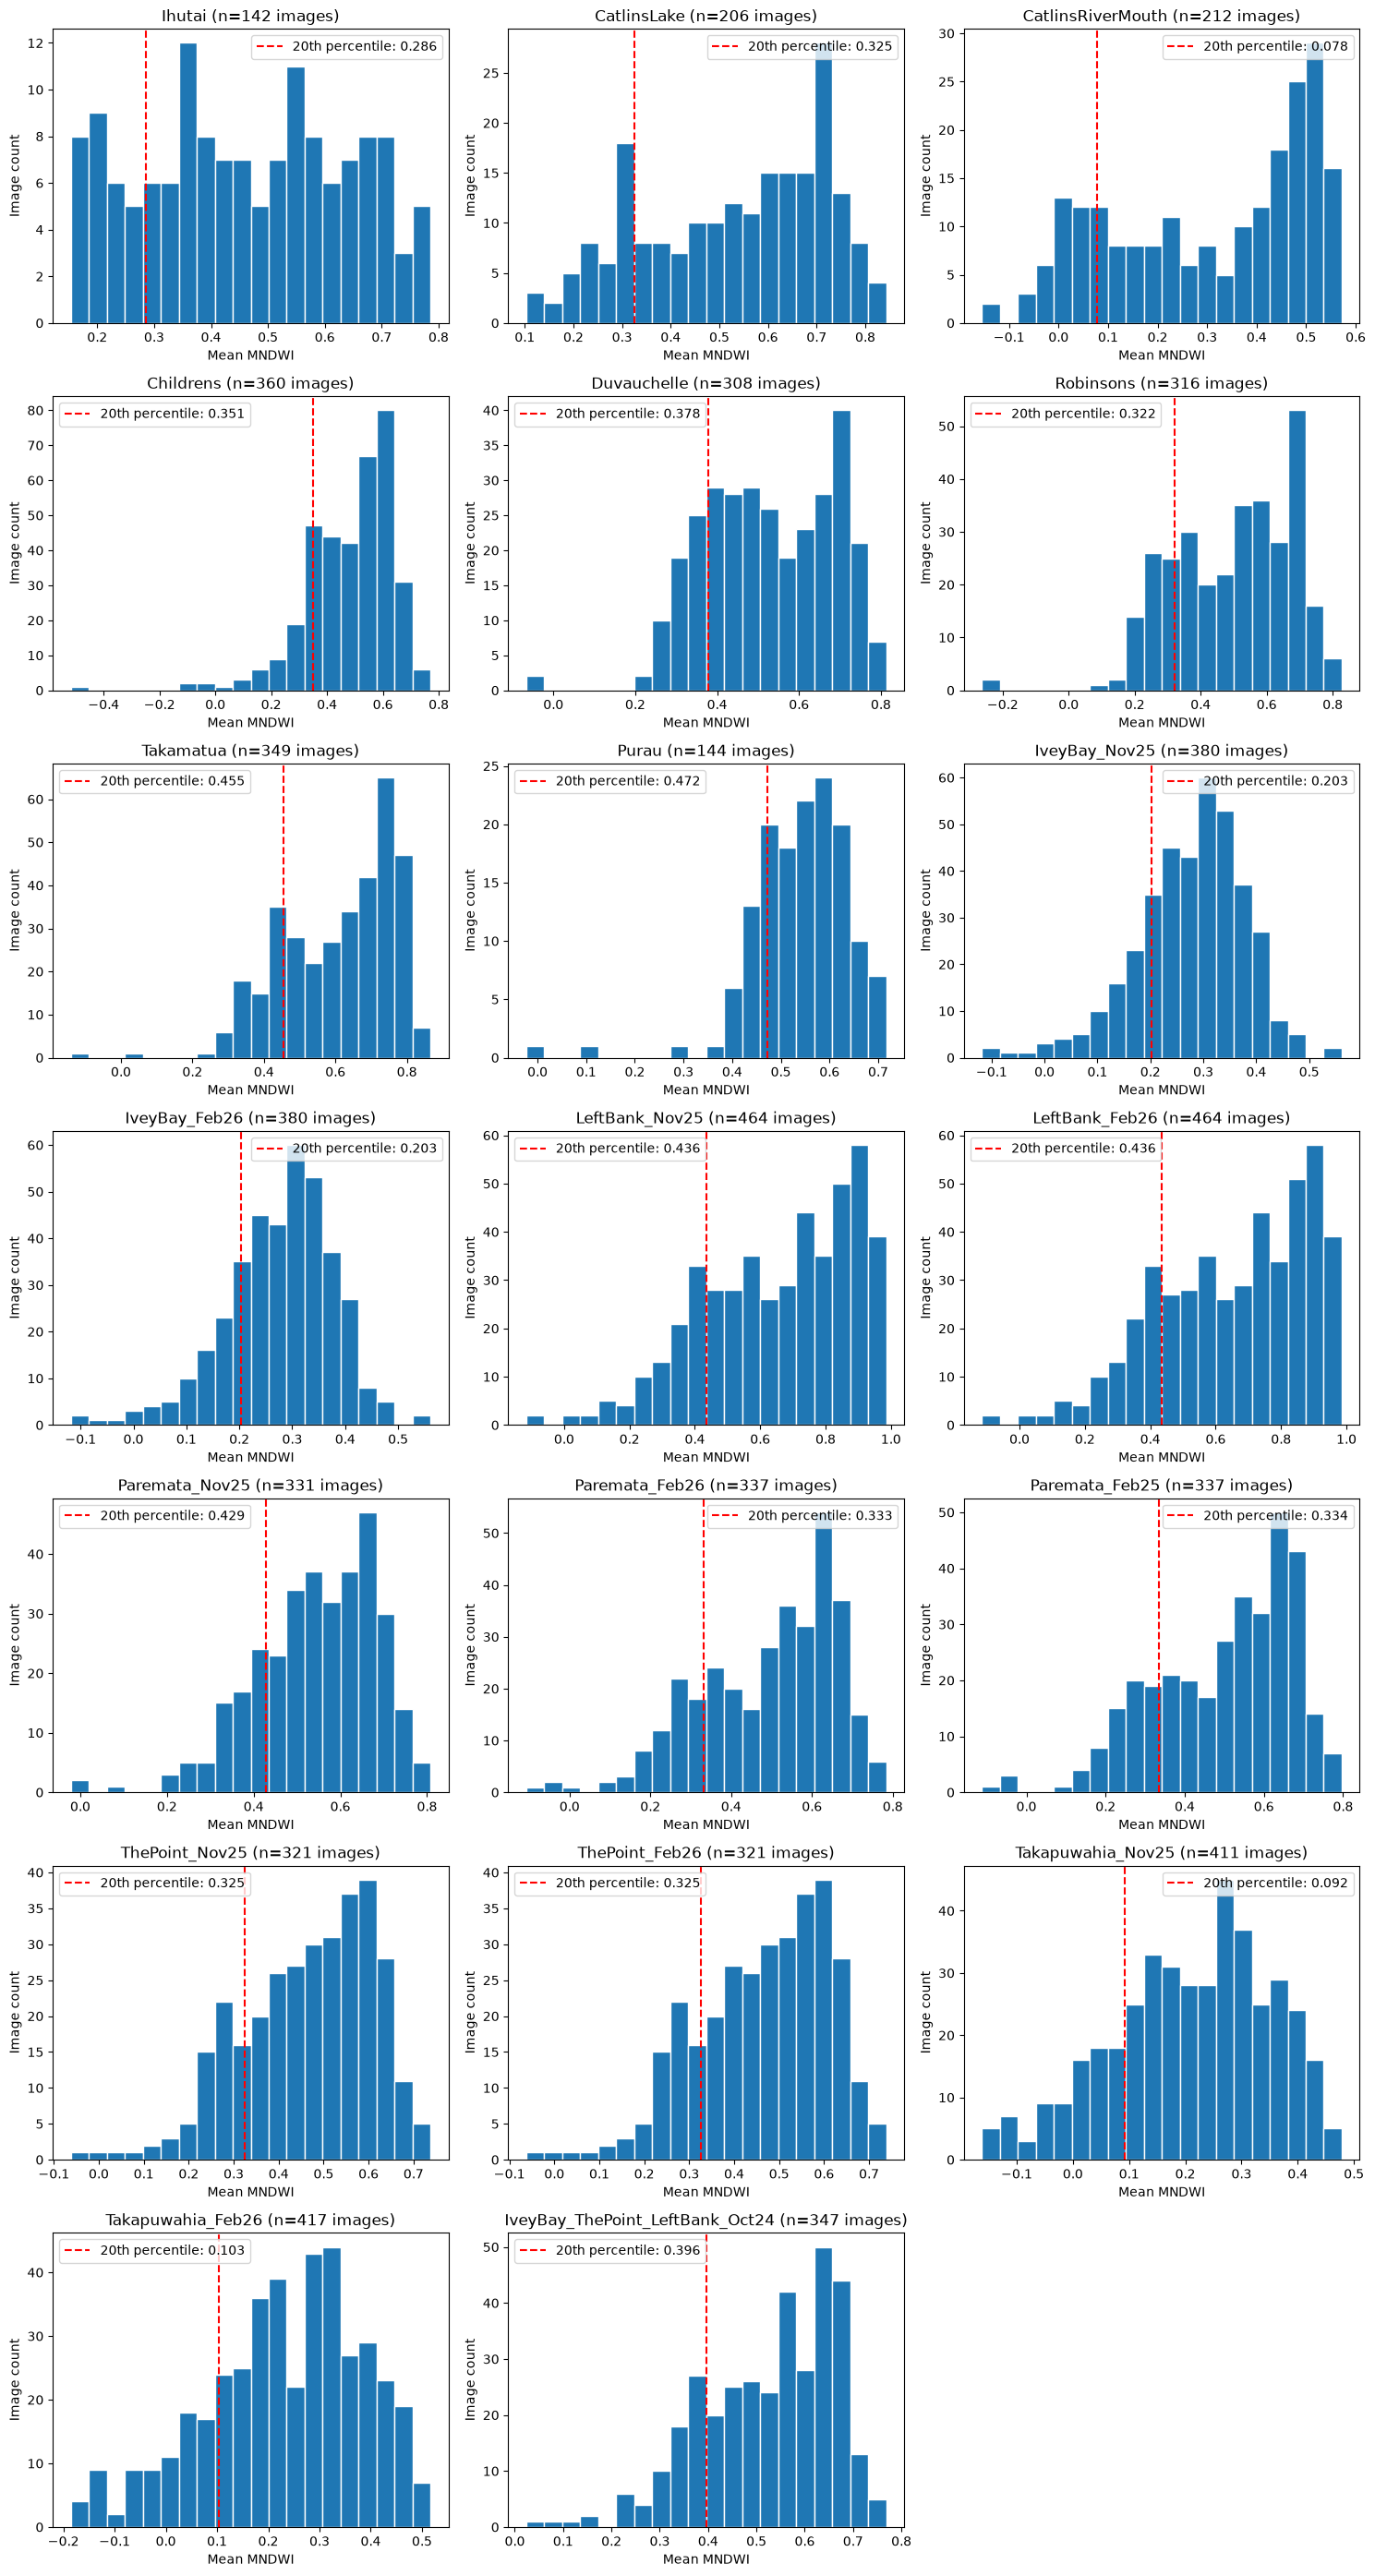

<Figure size 640x480 with 0 Axes>

In [8]:
mean_mndwi_all_sites = pandas.read_csv(satellite_path /"mean_mndwi.csv")

ncols = 3
nrows = int(numpy.ceil(len(sites) / ncols))

fig, axes = plt.subplots(
    nrows, ncols, figsize=(5 * ncols, 4 * nrows), squeeze=False
)

for axis, site in zip(axes.flat, sites):
    values = mean_mndwi_all_sites[mean_mndwi_all_sites["site"]==site].dropna()["mean_mndwi"]

    # Plot values in this site's histogram
    axis.hist(values, bins=20, edgecolor="white")
    axis.set_title(f"{site} (n={len(values)} images)")
    axis.set_xlabel("Mean MNDWI")
    axis.set_ylabel("Image count")

    if not values.empty:
        percentile_20 = numpy.percentile(values, 20)
        axis.axvline(
            percentile_20,
            color="red",
            linestyle="--",
            label=f"20th percentile: {percentile_20:.3f}",
        )
        axis.legend()

for axis in axes.flat[len(sites):]:
    axis.set_visible(False)

fig.tight_layout()
plt.show()
plt.savefig(output_path / "mean_mndwi_histograms.png")

# Thumbnails for 0% cloud band quality caluclations

In [3]:
data_path = utils.get_data_path()

years = [2016, 2017, 2018, 2019, 2020, 2021, 2022, 2023, 2024, 2025, 2026]

all_training_sites =  ["Ihutai", "CatlinsLake", "CatlinsRiverMouth", "Childrens", "Duvauchelle", "Robinsons", "Takamatua", "Purau",
              "IveyBay_Nov25", "IveyBay_Feb26", "LeftBank_Nov25", "LeftBank_Feb26", "Paremata_Nov25", "Paremata_Feb26",
              "Paremata_Feb25", "ThePoint_Nov25", "ThePoint_Feb26", "Takapuwahia_Nov25", "Takapuwahia_Feb26", "IveyBay_ThePoint_LeftBank_Oct24"]
sites = all_training_sites

baseline_max_cloud_cover = 0

_, satellite_path = utils.get_prediction_path(
    sample_method="sampling_2", method_2_threshold=0.5,
    model_max_cloud_cover=baseline_max_cloud_cover,
    predict_max_cloud_cover=baseline_max_cloud_cover,
    use_threshold=True, satellite_only=True) 

mean_mndwi_file = satellite_path / "mean_mndwi.csv"

In [4]:
sites=sites[0:12]

In [5]:
mean_mndwi_all_sites = []

for site in sites:
    mean_mndwi_series = []
    for year in years:
        print(f"{site}: year {year}")
    
        satellite_file = satellite_path / f"{site}_{year}_sentinel-2.nc"
        if not satellite_file.exists():
            print(f"WARNING no {satellite_file.name}.")
            continue

        # load in satellite file
        satellite_data = utils.load_satellite(filename=satellite_file, chunks=None)
        # calculate MNDWI layer
        mean_mndwi = sentinel2._mean_mndwi_by_date(satellite_data)
        mean_mndwi_series.append(
            mean_mndwi.compute().to_pandas()
        )
    mean_mndwi_series = pandas.concat(mean_mndwi_series)
    mean_mndwi_all_sites.append(mean_mndwi_series)

# for plotting the gallery / distributions
mean_mndwi_all_sites = pandas.concat(mean_mndwi_all_sites, keys=sites, names=["site", "time"]).rename("mean_mndwi")
mean_mndwi_all_sites.to_csv(mean_mndwi_file)

Ihutai: year 2016
WARNING no Ihutai_2016_sentinel-2.nc.
Ihutai: year 2017
WARNING no Ihutai_2017_sentinel-2.nc.
Ihutai: year 2018
WARNING no Ihutai_2018_sentinel-2.nc.
Ihutai: year 2019
WARNING no Ihutai_2019_sentinel-2.nc.
Ihutai: year 2020
WARNING no Ihutai_2020_sentinel-2.nc.
Ihutai: year 2021
WARNING no Ihutai_2021_sentinel-2.nc.
Ihutai: year 2022
Ihutai: year 2023
Ihutai: year 2024
Ihutai: year 2025
Ihutai: year 2026
CatlinsLake: year 2016
CatlinsLake: year 2017
CatlinsLake: year 2018
WARNING no CatlinsLake_2018_sentinel-2.nc.
CatlinsLake: year 2019
CatlinsLake: year 2020
CatlinsLake: year 2021
CatlinsLake: year 2022
CatlinsLake: year 2023
CatlinsLake: year 2024
CatlinsLake: year 2025
CatlinsLake: year 2026
CatlinsRiverMouth: year 2016
CatlinsRiverMouth: year 2017
CatlinsRiverMouth: year 2018
WARNING no CatlinsRiverMouth_2018_sentinel-2.nc.
CatlinsRiverMouth: year 2019
CatlinsRiverMouth: year 2020
CatlinsRiverMouth: year 2021
WARNING no CatlinsRiverMouth_2021_sentinel-2.nc.
Catlin

In [6]:
mean_mndwi = pandas.read_csv(mean_mndwi_file)
output_folder = satellite_path /  "rbg_thumbnails_mndwi_sorted"
output_folder.mkdir(exist_ok=True)

for site in sites:
    print(f"{site}")
    gallery_file = output_folder / f"{site}.html"
    if gallery_file.exists():
        continue
    plotting.create_rgb_gallery(site_name=site,
                                mndwi=mean_mndwi, 
                                gallery_file=gallery_file, 
                                years=years,
                                max_cloud_cover=baseline_max_cloud_cover,
                                satellite_path=satellite_path)

Ihutai
CatlinsLake
CatlinsRiverMouth
Childrens
Duvauchelle
Robinsons
Takamatua
	Site Takamatua - create gallery
  Saved C:\Local\repos\seagrass-detection\data\predictions\tide_thresholded_cloud_0\satellite_images\rbg_thumbnails_mndwi_sorted\Takamatua.html
Purau
	Site Purau - create gallery
  Saved C:\Local\repos\seagrass-detection\data\predictions\tide_thresholded_cloud_0\satellite_images\rbg_thumbnails_mndwi_sorted\Purau.html
IveyBay_Nov25
	Site IveyBay_Nov25 - create gallery
  Saved C:\Local\repos\seagrass-detection\data\predictions\tide_thresholded_cloud_0\satellite_images\rbg_thumbnails_mndwi_sorted\IveyBay_Nov25.html
IveyBay_Feb26
	Site IveyBay_Feb26 - create gallery
  Saved C:\Local\repos\seagrass-detection\data\predictions\tide_thresholded_cloud_0\satellite_images\rbg_thumbnails_mndwi_sorted\IveyBay_Feb26.html
LeftBank_Nov25
	Site LeftBank_Nov25 - create gallery
  Saved C:\Local\repos\seagrass-detection\data\predictions\tide_thresholded_cloud_0\satellite_images\rbg_thumbnails_mn

# Look at 0% cloud and review MNDWI

In [19]:
data_path = utils.get_data_path()
utils.create_data_folders()

In [20]:
all_training_sites =  ["Ihutai", "CatlinsLake", "CatlinsRiverMouth", "Childrens", "Duvauchelle", "Robinsons", "Takamatua", "Purau",
              "IveyBay_Nov25", "IveyBay_Feb26", "LeftBank_Nov25", "LeftBank_Feb26", "Paremata_Nov25", "Paremata_Feb26",
              "Paremata_Feb25", "ThePoint_Nov25", "ThePoint_Feb26", "Takapuwahia_Nov25", "Takapuwahia_Feb26", "IveyBay_ThePoint_LeftBank_Oct24"]

sites = all_training_sites
mndwi_file = data_path / "mndwi_low_tide_thresholds.csv"
baseline_max_cloud_cover = 0
years = [2016, 2017, 2018, 2019, 2020, 2021, 2022, 2023, 2024, 2025, 2026]

In [21]:
_, satellite_path = utils.get_prediction_path(
    sample_method="sampling_2", method_2_threshold=0.5,
    model_max_cloud_cover=baseline_max_cloud_cover,
    predict_max_cloud_cover=baseline_max_cloud_cover,
    use_threshold=True, satellite_only=True) 

In [22]:
mndwi_thresholds = pandas.read_csv(mndwi_file)

In [23]:
mndwi_thresholds

,site,threshold
0,Ihutai,0.285990
1,CatlinsLake,0.324971
2,CatlinsRiverMouth,0.077602
3,Childrens,0.351367
4,Duvauchelle,0.378407
5,Robinsons,0.321775
6,Takamatua,0.455245
7,Purau,0.472248
8,IveyBay_Nov25,0.202730
9,IveyBay_Feb26,0.202730


In [24]:
site = sites[0]
mndwi_threshold = mndwi_thresholds.loc[mndwi_thresholds["site"] == site, "threshold",].squeeze()

year = years[-1]
print(f"{site}: year {year}")

satellite_file = satellite_path / f"{site}_{year}_sentinel-2.nc"
site_polygon_file = utils.get_site_polygon_path(site)

if not satellite_file.exists():
    print(f"\tSave satellite image of the site {site} MNDWI thresholded and cloud filtered in the year {year}")
    site_polygon = geopandas.read_file(site_polygon_file)
    satellite_data = sentinel2.get_cloud_filtered_images_in_year(
        geometry=site_polygon,
        max_cloud_cover=baseline_max_cloud_cover,
        year=year,
    )

Ihutai: year 2026
	Save satellite image of the site Ihutai MNDWI thresholded and cloud filtered in the year 2026
	Getting images
	Low cloud tiles: 6 from the total tiles of 55. Cloud percentages [100.   60.6   0.  100.   74.2 100.    0.   45.7 100.  100.    0.  100.
   1.2 100.   13.1   9.    0.  100.    0.2  89.6 100.  100.    2.9   0.
   0.  100.  100.   59.7 100.    7.   16.5  31.4   0.2  99.5   0.6 100.
   0.    6.1  99.8   4.  100.    0.  100.   84.   98.5  98.6  44.6 100.
 100.    0.    0.   93.4  15.9   0.  100. ] Kept [False False  True False False False  True False False False  True False
 False False False False  True False False False False False False False
 False False False False False False False False False False False False
 False False False False False  True False False False False False False
 False False  True False False False False]


In [25]:
satellite_data

<xarray.Dataset> Size: 40MB
Dimensions:      (y: 581, x: 441, time: 6)
Coordinates:
  * y            (y) float64 5kB 5.181e+06 5.181e+06 ... 5.175e+06 5.175e+06
  * x            (x) float64 4kB 6.37e+05 6.37e+05 ... 6.414e+05 6.414e+05
  * time         (time) datetime64[us] 48B 2026-01-12T22:25:39.024000 ... 202...
    spatial_ref  int64 8B 0
Data variables: (12/13)
    B01          (time, y, x) uint16 3MB 0 0 0 0 0 0 0 0 0 ... 0 0 0 0 0 0 0 0 0
    B02          (time, y, x) uint16 3MB 0 0 0 0 0 0 0 0 0 ... 0 0 0 0 0 0 0 0 0
    B03          (time, y, x) uint16 3MB 0 0 0 0 0 0 0 0 0 ... 0 0 0 0 0 0 0 0 0
    B04          (time, y, x) uint16 3MB 0 0 0 0 0 0 0 0 0 ... 0 0 0 0 0 0 0 0 0
    B05          (time, y, x) uint16 3MB 0 0 0 0 0 0 0 0 0 ... 0 0 0 0 0 0 0 0 0
    B06          (time, y, x) uint16 3MB 0 0 0 0 0 0 0 0 0 ... 0 0 0 0 0 0 0 0 0
    ...           ...
    B08          (time, y, x) uint16 3MB 0 0 0 0 0 0 0 0 0 ... 0 0 0 0 0 0 0 0 0
    B09          (time, y, x) uint16 3MB 0 0 0 0 0 0 0 0 0 ... 0 0 0 0 0 0 0 0 0
    B11          (time, y, x) uint16 3MB 0 0 0 0 0 0 0 0 0 ... 0 0 0 0 0 0 0 0 0
    B12          (time, y, x) uint16 3MB 0 0 0 0 0 0 0 0 0 ... 0 0 0 0 0 0 0 0 0
    B8A          (time, y, x) uint16 3MB 0 0 0 0 0 0 0 0 0 ... 0 0 0 0 0 0 0 0 0
    SCL          (time, y, x) uint16 3MB 0 0 0 0 0 0 0 0 0 ... 0 0 0 0 0 0 0 0 0

In [26]:
mndwi = sentinel2._mean_mndwi_by_date(satellite_data)

In [27]:
mndwi

<xarray.DataArray (time: 6)> Size: 24B
array([0.40079594, 0.39971694, 0.67407787, 0.7567633 , 0.6636877 ,
       0.5910423 ], dtype=float32)
Coordinates:
  * time         (time) datetime64[us] 48B 2026-01-12T22:25:39.024000 ... 202...
    spatial_ref  int64 8B 0
Attributes:
    _FillValue:  0

In [29]:
green = satellite_data["B03"].astype(numpy.float32)
swir1 = satellite_data["B11"].astype(numpy.float32)
valid_pixels = (
    satellite_data["SCL"].notnull()
    & ~satellite_data["SCL"].isin(sentinel2.SCL_TO_IGNORE)
    & (green > 0)
    & (swir1 > 0)
)

((green - swir1) / (green + swir1)).where(valid_pixels).mean(dim=["x", "y"], skipna=True)

<xarray.DataArray (time: 6)> Size: 24B
array([0.40079594, 0.39971694, 0.67407787, 0.67404205, 0.6636877 ,
       0.5910423 ], dtype=float32)
Coordinates:
  * time         (time) datetime64[us] 48B 2026-01-12T22:25:39.024000 ... 202...
    spatial_ref  int64 8B 0
Attributes:
    _FillValue:  0

In [31]:
satellite_data.time

<xarray.DataArray 'time' (time: 6)> Size: 48B
array(['2026-01-12T22:25:39.024000', '2026-02-01T22:25:39.024000',
       '2026-02-21T22:25:39.024000', '2026-03-23T22:25:39.024000',
       '2026-08-05T22:25:41.025000', '2026-09-19T22:25:39.024000'],
      dtype='datetime64[us]')
Coordinates:
  * time         (time) datetime64[us] 48B 2026-01-12T22:25:39.024000 ... 202...
    spatial_ref  int64 8B 0

In [18]:
pandas.read_csv(data_path / "band_quality_baseline_tide_api.csv")

,site,band,median,mad,mad_raw,n_images
0,Ihutai,B04,502.00,51.494618,8.00,16
1,Ihutai,B03,642.00,59.765278,31.00,16
2,Ihutai,B02,568.00,53.913715,29.00,16
3,CatlinsLake,B04,356.00,57.154375,45.50,50
4,CatlinsLake,B03,378.00,63.650714,56.00,50
5,CatlinsLake,B02,262.00,52.527054,44.00,50
6,CatlinsRiverMouth,B04,814.00,93.410750,96.00,55
7,CatlinsRiverMouth,B03,877.00,85.140667,86.00,55
8,CatlinsRiverMouth,B02,637.00,50.491917,42.00,55
9,Childrens,B04,423.00,82.479365,82.00,159


In [19]:
pandas.read_csv(data_path / "band_quality_baseline_without_RGB_0_values.csv")

,site,band,median,mad,mad_raw,n_images
0,Ihutai,B04,434.0,92.257319,91.0,39
1,Ihutai,B03,642.0,66.129430,62.0,39
2,Ihutai,B02,570.0,60.288136,59.0,39
3,CatlinsLake,B04,339.5,66.536998,58.0,66
4,CatlinsLake,B03,384.5,53.321353,47.0,66
5,CatlinsLake,B02,274.0,47.988372,43.5,66
6,CatlinsRiverMouth,B04,754.5,126.802273,137.5,60
7,CatlinsRiverMouth,B03,839.0,102.545455,112.0,60
8,CatlinsRiverMouth,B02,555.0,80.575000,86.5,60


In [37]:
_, satellite_path = utils.get_prediction_path(
    sample_method="sampling_2", method_2_threshold=0.5,
    model_max_cloud_cover=baseline_max_cloud_cover,
    predict_max_cloud_cover=baseline_max_cloud_cover,
    use_threshold=True, satellite_only=True) 
baseline = sentinel2.compute_and_save_band_quality_baseline(
    training_sites=sites[0:6],
    satellite_images_paths=[satellite_path],
)
baseline

	Saved band quality baseline for 6 sites to C:\Local\repos\seagrass-detection\data\band_quality_baseline.csv


,site,band,median,mad,mad_raw,n_images
0,Ihutai,B04,564.0,73.908699,46.0,7
1,Ihutai,B03,668.0,59.681309,34.0,7
2,Ihutai,B02,570.0,56.911283,38.0,7
3,CatlinsLake,B04,451.0,56.570579,33.0,23
4,CatlinsLake,B03,424.0,56.009194,45.0,23
5,CatlinsLake,B02,315.0,48.269876,35.0,23
6,CatlinsRiverMouth,B04,849.0,79.035695,75.0,23
7,CatlinsRiverMouth,B03,932.0,76.869659,84.0,23
8,CatlinsRiverMouth,B02,637.0,63.781504,64.0,23
9,Childrens,B04,432.5,102.343429,108.0,66
